# Pronóstico mensual de tarifas spot de camión refrigerado por lane
### Proyecto final: demostración de Machine Learning (prueba de concepto)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jmartinezvogel/reefer-spot-rate-forecasting/blob/main/ML_ProyectoFinal_Equipo3.ipynb)

**Maestría en Inteligencia Artificial Aplicada** · Inteligencia Artificial y Aprendizaje Automático (TC4058.2)
**Profesor:** Oscar Daniel Ortiz Esquivel · **Equipo 3**

| Integrante | Matrícula |
|---|---|
| Jaime Alfonso Martínez Vogel | A01283238 |
| Héctor de Luna Aguilar | A01610988 |

**El caso.** Un distribuidor de frutas y verduras frescas (anónimo) mueve producto en camiones refrigerados y paga flete *spot*. Necesita saber **cuánto le costará cada lane (origen y destino) el mes siguiente** para armar su presupuesto de flete y decidir cuándo conviene cotizar un contrato.

**Contenido.** Cargamos y revisamos los datos, los preparamos, entrenamos y validamos el modelo, lo comparamos contra referencias simples, revisamos tres predicciones con su valor real y terminamos con cómo se traduce una predicción en una decisión del negocio.

**Cambios por la retroalimentación del Entregable 4.**
1. **Independencia de la prueba:** explicamos cómo la cuidamos y qué tan optimista es el resultado.
2. **¿Vale la pena el algoritmo?** Comparamos el modelo contra la regla simple de la última semana con su propio intervalo de confianza.

**Cómo ejecutarlo.** `pip install -r requirements.txt` y después **Run All**. Corre completo en menos de un minuto, sin internet, porque los datos originales vienen en `data/raw`. Este notebook es la versión resumida del notebook del Entregable 4 y reproduce exactamente sus cifras.

In [1]:
# Solo en Google Colab: clona el repositorio para tener la carpeta data/ (en una computadora no hace nada)
import os, subprocess, sys

if "google.colab" in sys.modules and not os.path.exists("data/raw"):
    subprocess.run(["git", "clone", "-q", "https://github.com/jmartinezvogel/reefer-spot-rate-forecasting.git"], check=True)
    os.chdir("reefer-spot-rate-forecasting")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlrd"], check=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
AZUL, GRIS, NARANJA = "#1f618d", "#9e9e9e", "#f0b27a"
SEMILLA = 42   # misma semilla del E4 para que los resultados se repitan


def formatear(tabla, formatos):
    # Copia de la tabla con los números como texto legible, para que se vea igual en Jupyter, VS Code y Colab
    t = tabla.copy()
    for columna, formato in formatos.items():
        t[columna] = t[columna].map(formato.format)
    return t
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.3.3 | scikit-learn 1.9.1


## 1. Carga y vista preliminar de los datos

Usamos dos fuentes públicas del gobierno de EE. UU., sin datos personales:

| Fuente | Qué trae | Archivo |
|---|---|---|
| USDA AgTransport, *Refrigerated Truck Rates and Availability* | Tarifa spot semanal por origen, destino y producto (USD por carga) | `usda_refrigerated_truck_rates_raw.csv.gz` |
| EIA, *Weekly U.S. No 2 Diesel Retail Prices* | Precio semanal del diésel (USD por galón) | `eia_diesel_semanal_raw.xls` |

In [3]:
ARCHIVO_USDA = "data/raw/usda_refrigerated_truck_rates_raw.csv.gz"
ARCHIVO_DIESEL = "data/raw/eia_diesel_semanal_raw.xls"

usda = pd.read_csv(ARCHIVO_USDA, dtype=str)            # la API entrega todo como texto
usda["date"] = pd.to_datetime(usda["date"])
for columna in ["midpoint", "weeklow", "weekhigh", "distance", "availability"]:
    usda[columna] = pd.to_numeric(usda[columna], errors="coerce")

print(f"USDA: {len(usda):,} registros semanales, del {usda['date'].min().date()} al {usda['date'].max().date()}")
usda[["date", "origin", "destination", "commodity", "distance", "weeklow", "weekhigh", "midpoint", "availability"]].head()

USDA: 207,024 registros semanales, del 2000-01-04 al 2026-10-27


,date,origin,destination,commodity,distance,weeklow,weekhigh,midpoint,availability
0,2000-01-04,"IMPERIAL, PALO VERDE, AND COACHELLA VALLEYS, C...",ATLANTA,LETTUCE AND MIXED VEGETABLES,"2,100.00","2,100.00","2,400.00","2,250.00",3
1,2000-01-04,"IMPERIAL, PALO VERDE, AND COACHELLA VALLEYS, C...",CHICAGO,LETTUCE AND MIXED VEGETABLES,"2,030.00","2,000.00","2,400.00","2,200.00",3
2,2000-01-04,"IMPERIAL, PALO VERDE, AND COACHELLA VALLEYS, C...",DALLAS,LETTUCE AND MIXED VEGETABLES,"1,300.00","1,500.00","2,000.00","1,850.00",3
3,2000-01-04,"IMPERIAL, PALO VERDE, AND COACHELLA VALLEYS, C...",NEW YORK,LETTUCE AND MIXED VEGETABLES,"2,700.00","3,000.00","3,400.00","3,200.00",3
4,2000-01-04,"IMPERIAL, PALO VERDE, AND COACHELLA VALLEYS, C...",ATLANTA,LETTUCE AND MIXED VEGETABLES,"2,100.00","2,100.00","2,400.00","2,250.00",3


In [4]:
diesel = pd.read_excel(ARCHIVO_DIESEL, sheet_name="Data 1", skiprows=2).iloc[:, :2]
diesel.columns = ["fecha", "diesel"]
diesel = diesel.assign(fecha=pd.to_datetime(diesel["fecha"], errors="coerce"),
                       diesel=pd.to_numeric(diesel["diesel"], errors="coerce")).dropna()
print(f"Diésel: {len(diesel):,} semanas, del {diesel['fecha'].min().date()} al {diesel['fecha'].max().date()}")
diesel.tail(3)

Diésel: 1,703 semanas, del 1994-03-21 al 2026-11-02


,fecha,diesel
1700,2026-10-19,6.28
1701,2026-10-26,6.35
1702,2026-11-02,6.29


**Qué vemos.** Cada renglón de USDA es la tarifa de **una semana** para un origen, un destino y un producto. La columna `midpoint` es nuestra variable objetivo (USD por carga) y `availability` es la disponibilidad de camiones (1 = sobran, 5 = escasean). La distancia de cada lane viene en millas.

### 1.1 Hallazgos principales del análisis exploratorio (resumen del Entregable 3)

Tres gráficas que explican el problema. Usamos la tarifa **por milla** para comparar entre años, porque la tarifa por carga depende de qué tan largas son las lanes que se reportan cada año.

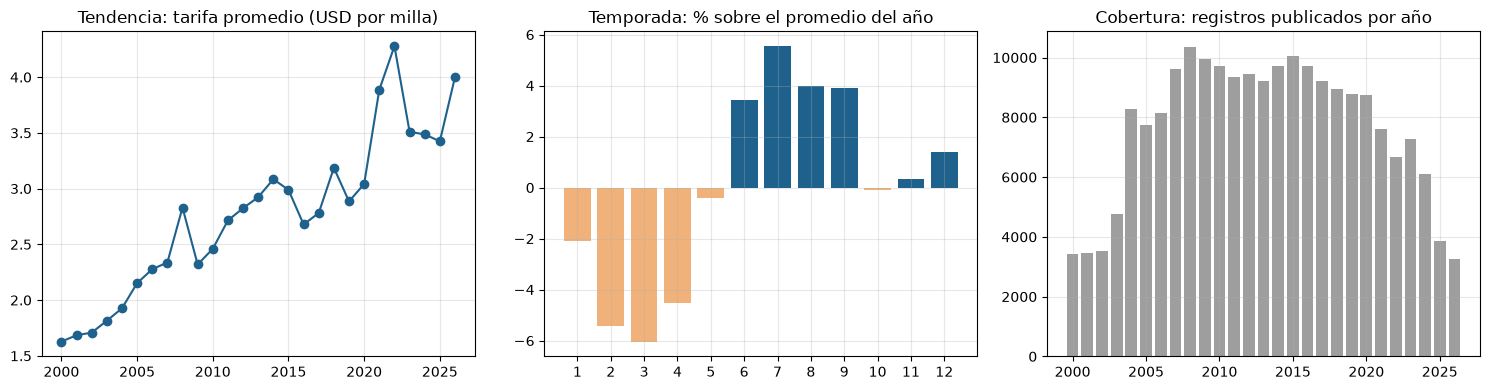

Máximo: 4.28 USD por milla en 2022 | julio +5.5% | marzo -6.0%
Registros por año: 9,728 en promedio de 2008 a 2016 contra 3,875 en 2025
Correlación tarifa por milla y diésel: 0.79 en niveles, 0.09 en cambios mensuales


In [5]:
u = usda.assign(rpm=pd.to_numeric(usda["rpm"], errors="coerce"), anio=usda["date"].dt.year, num_mes=usda["date"].dt.month)
rpm_anual = u.groupby("anio")["rpm"].mean()
indice = u[u["anio"] < 2026].groupby(["anio", "num_mes"])["rpm"].mean().reset_index()     # 2026 queda fuera: está incompleto
indice["indice"] = indice["rpm"] / indice.groupby("anio")["rpm"].transform("mean")          # cada mes contra el promedio de su año
temporada = (indice.groupby("num_mes")["indice"].mean() - 1) * 100
registros = u.groupby("anio").size()

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].plot(rpm_anual.index, rpm_anual.values, "o-", color=AZUL)
ejes[0].set_title("Tendencia: tarifa promedio (USD por milla)")
ejes[1].bar(temporada.index, temporada.values, color=[AZUL if v > 0 else NARANJA for v in temporada.values])
ejes[1].set_title("Temporada: % sobre el promedio del año")
ejes[1].set_xticks(range(1, 13))
ejes[2].bar(registros.index, registros.values, color=GRIS)
ejes[2].set_title("Cobertura: registros publicados por año")
plt.tight_layout()
plt.show()

rpm_mes = u.groupby(u["date"].dt.to_period("M"))["rpm"].median()
diesel_mes = diesel.groupby(diesel["fecha"].dt.to_period("M"))["diesel"].mean()
juntos = pd.concat([rpm_mes.rename("rpm"), diesel_mes.rename("diesel")], axis=1).dropna()
print(f"Máximo: {rpm_anual.max():.2f} USD por milla en {rpm_anual.idxmax()} | julio {temporada[7]:+.1f}% | marzo {temporada[3]:+.1f}%")
print(f"Registros por año: {registros.loc[2008:2016].mean():,.0f} en promedio de 2008 a 2016 contra {registros[2025]:,} en 2025")
print(f"Correlación tarifa por milla y diésel: {juntos['rpm'].corr(juntos['diesel']):.2f} en niveles, "
      f"{juntos['rpm'].pct_change().corr(juntos['diesel'].pct_change()):.2f} en cambios mensuales")

**Interpretación.**
- **Tendencia con choques:** la tarifa sube en el tiempo con saltos fuertes en 2008, 2021-22 (máximo de 4.28 USD por milla en 2022) y 2026. Por eso validamos siempre en orden temporal.
- **Temporada:** julio es 5.5% más caro que el promedio de su año y marzo 6% más barato. Por eso el modelo usa el mes del año y la estacionalidad propia de cada lane.
- **Cobertura:** cada vez menos lanes reportan (de unos 9,700 registros por año entre 2008 y 2016 a 3,875 en 2025), lo que obliga a elegir las lanes con cuidado.
- **Diésel:** se mueve junto con la tarifa en el largo plazo (0.79), pero su cambio mensual casi no explica el cambio de la tarifa (0.09).

## 2. Transformaciones principales y su justificación

| Paso | Qué hacemos | Por qué |
|---|---|---|
| 2.1 Limpieza | Quitamos duplicados por semana, origen, destino y producto; `midpoint` fuera de su rango semanal; filas sin `midpoint` o sin distancia | Los duplicados dan doble peso a una lane, los fuera de rango son imposibles y sin `midpoint` no hay respuesta que aprender |
| 2.2 Panel mensual | Mediana de las semanas de cada lane en cada mes y solo meses completos | La pregunta es mensual y la mediana resiste semanas extremas |
| 2.3 Variables | Rezagos y cambios que **ya se conocen** al cerrar el mes anterior | Evitar fuga de información: el modelo nunca ve el futuro |
| 2.4 Lanes por corte | Las lanes se eligen con la información disponible en cada fecha de corte | Evitar el sesgo de supervivencia (retroalimentación del E3) |

In [6]:
# 2.1 Limpieza
limpio = usda.drop_duplicates(subset=["date", "origin", "destination", "commodity"])
limpio = limpio[~((limpio["midpoint"] < limpio["weeklow"]) | (limpio["midpoint"] > limpio["weekhigh"]))]
limpio = limpio.dropna(subset=["midpoint", "distance"])
limpio = limpio.assign(lane=limpio["origin"] + " → " + limpio["destination"], mes=limpio["date"].dt.to_period("M"))
print(f"Registros: {len(usda):,} → {len(limpio):,} (se quita {1 - len(limpio) / len(usda):.2%})")

Registros: 207,024 → 201,505 (se quita 2.67%)


In [7]:
# 2.2 Panel mensual: un renglón por lane y mes
ULTIMO_MES = pd.Period("2026-10", freq="M")   # último mes completo (la siguiente semana publicada ya cae en noviembre)
base = (limpio.groupby(["origin", "destination", "lane", "mes"])
        .agg(tarifa=("midpoint", "median"), disponibilidad=("availability", "mean"), distancia=("distance", "median"))
        .reset_index())
base = base[base["mes"] <= ULTIMO_MES]

# Primera y última semana publicada de cada lane-mes (la última semana es la "idea central" del modelo)
semanal = limpio.groupby(["lane", "date"])["midpoint"].median().reset_index().sort_values("date")
semanas = (semanal.assign(mes=semanal["date"].dt.to_period("M")).groupby(["lane", "mes"])
           .agg(primera_semana=("midpoint", "first"), ultima_semana=("midpoint", "last"), fecha_ultima_semana=("date", "last"))
           .reset_index())

# Diésel: promedio mensual
diesel_mensual = diesel.groupby(diesel["fecha"].dt.to_period("M"))["diesel"].mean().rename_axis("mes").reset_index()
diesel_mensual = diesel_mensual[diesel_mensual["mes"] <= ULTIMO_MES]
print(f"Panel mensual: {len(base):,} lane-meses de {base['lane'].nunique()} lanes, de {base['mes'].min()} a {ULTIMO_MES}")

Panel mensual: 49,929 lane-meses de 792 lanes, de 2000-01 a 2026-10


### 2.3 Variables: todo lo que se conoce al cerrar el mes anterior

**La idea central.** Cuando compras pronostica noviembre, ya conoce **la última semana de octubre**. Si las tarifas subieron a fines de octubre, lo más probable es que noviembre arranque en ese nivel y no en la mediana de octubre. Por eso el modelo **parte de la última semana conocida** y predice cuánto ajustarla:

> Pronóstico (USD) = última semana conocida × e^(0.25 × cambio que predice el modelo)

El 0.25 es un *factor de amortiguamiento* elegido con la validación cruzada: el modelo solo aplica una cuarta parte del cambio que predice, porque aplicarlo completo exageraba los movimientos.

| Grupo | Variables |
|---|---|
| Cierre del mes anterior | `semana_final_lag1` (cuánto cerró la última semana arriba o abajo de la mediana), `tendencia_mes_lag1` (primera contra última semana) |
| Historia de la lane | `cambio_lane_lag1` (cambio del mes anterior), `cambio_lane_hace12` (mismo mes del año pasado) |
| Mercado y costos | `cambio_mercado_lag1`, `cambio_mercado_lag12`, `cambio_diesel_lag1`, `disponibilidad_lag1` |
| Fijas y calendario | `distancia`, `mes_sin`, `mes_cos` (mes del año en forma cíclica) |

In [8]:
def rezago(tabla, origen, columnas, meses, llave):
    # Movemos el mes y unimos: si ese mes no existe, el rezago queda vacío (no toma otro mes por error)
    anterior = origen[llave + columnas].copy()
    anterior["mes"] = anterior["mes"] + meses
    return tabla.merge(anterior.rename(columns={c: f"{c}_lag{meses}" for c in columnas}), on=llave, how="left")


def crear_variables(panel):
    t = panel.copy()
    for meses in [1, 2, 12, 13]:
        t = rezago(t, panel, ["tarifa"], meses, ["lane", "mes"])
    t = rezago(t, panel, ["disponibilidad"], 1, ["lane", "mes"])
    t = rezago(t, semanas, ["primera_semana", "ultima_semana", "fecha_ultima_semana"], 1, ["lane", "mes"])

    t["cambio_lane"] = np.log(t["tarifa"] / t["tarifa_lag1"])
    mercado = t.groupby("mes")["cambio_lane"].mean().rename("cambio_mercado").reset_index()
    diesel_cambio = diesel_mensual.assign(cambio_diesel=np.log(diesel_mensual["diesel"]).diff())
    t = rezago(t, mercado, ["cambio_mercado"], 1, ["mes"])
    t = rezago(t, mercado, ["cambio_mercado"], 12, ["mes"])
    t = rezago(t, diesel_cambio, ["cambio_diesel"], 1, ["mes"])

    t["semana_final_lag1"] = np.log(t["ultima_semana_lag1"] / t["tarifa_lag1"])
    t["tendencia_mes_lag1"] = np.log(t["ultima_semana_lag1"] / t["primera_semana_lag1"])
    t["cambio_lane_lag1"] = np.log(t["tarifa_lag1"] / t["tarifa_lag2"])
    t["cambio_lane_hace12"] = np.log(t["tarifa_lag12"] / t["tarifa_lag13"])
    t["mes_sin"] = np.sin(2 * np.pi * t["mes"].dt.month / 12)
    t["mes_cos"] = np.cos(2 * np.pi * t["mes"].dt.month / 12)

    t[TARGET] = np.log(t["tarifa"] / t["ultima_semana_lag1"])   # lo que aprende el modelo: cambio contra la última semana
    return t.sort_values(["mes", "lane"]).reset_index(drop=True)


TARGET = "cambio_vs_semana"
ENTRADAS = ["semana_final_lag1", "tendencia_mes_lag1", "cambio_lane_lag1", "cambio_lane_hace12",
            "cambio_mercado_lag1", "cambio_mercado_lag12", "cambio_diesel_lag1", "disponibilidad_lag1",
            "distancia", "mes_sin", "mes_cos"]

panel_total = crear_variables(base)
con_semana = panel_total.dropna(subset=["fecha_ultima_semana_lag1"])
print(f"Correlación entre la tarifa de un mes y la del mes anterior: {panel_total[['tarifa', 'tarifa_lag1']].corr().iloc[0, 1]:.2f}")
print("¿La última semana usada siempre es anterior al mes que se pronostica?",
      bool((con_semana["fecha_ultima_semana_lag1"] < con_semana["mes"].dt.start_time).all()))
desarrollo_total = panel_total[panel_total["mes"] <= pd.Period("2024-12", freq="M")]
print("Correlación con el cambio del mes siguiente (solo datos hasta 2024):")
desarrollo_total[ENTRADAS[:8] + ["cambio_lane"]].corr()["cambio_lane"].drop("cambio_lane").sort_values(ascending=False).round(2)

Correlación entre la tarifa de un mes y la del mes anterior: 0.99
¿La última semana usada siempre es anterior al mes que se pronostica? True
Correlación con el cambio del mes siguiente (solo datos hasta 2024):


semana_final_lag1      0.53
tendencia_mes_lag1     0.41
cambio_lane_hace12     0.31
cambio_mercado_lag12   0.21
cambio_diesel_lag1     0.12
cambio_mercado_lag1    0.12
disponibilidad_lag1    0.04
cambio_lane_lag1       0.01
Name: cambio_lane, dtype: float64

**Interpretación.** La tarifa de un mes casi repite la del mes anterior (correlación de 0.99), por eso el baseline ingenuo es tan fuerte. La entrada más relacionada con el cambio del mes siguiente es cómo cerró la última semana del mes anterior (0.53), seguida de la tendencia dentro de ese mes (0.41) y de la estacionalidad propia de la lane (0.31). El diésel (0.12) y la disponibilidad de camiones (0.04) aportan poco a corto plazo, igual que en el análisis exploratorio.

In [9]:
# 2.4 Selección de lanes en cada corte: al menos 36 meses con dato y actividad en los últimos 12, contando SOLO hasta el corte
def lanes_elegibles(corte):
    historia = base[base["mes"] <= corte].groupby("lane").agg(meses=("tarifa", "count"), ultimo=("mes", "max"))
    return sorted(historia.index[(historia["ultimo"] > corte - 12) & (historia["meses"] >= 36)])


def preparar_corte(corte):
    elegibles = lanes_elegibles(corte)
    datos = crear_variables(base[base["lane"].isin(elegibles)])
    return elegibles, datos.dropna(subset=["tarifa", "tarifa_lag1"]).reset_index(drop=True)


FIN_DESARROLLO = pd.Period("2024-12", freq="M")
lanes_hoy, lanes_2024 = lanes_elegibles(ULTIMO_MES), lanes_elegibles(FIN_DESARROLLO)
print(f"Lanes elegibles en dic-2024: {len(lanes_2024)} | en oct-2026: {len(lanes_hoy)}")
print(f"{len(set(lanes_2024) - set(lanes_hoy))} lanes elegibles en 2024 ya no existen en 2026: "
      "si eligiéramos con la lista de hoy evaluaríamos el pasado solo con las lanes que 'sobrevivieron'")

Lanes elegibles en dic-2024: 151 | en oct-2026: 94
79 lanes elegibles en 2024 ya no existen en 2026: si eligiéramos con la lista de hoy evaluaríamos el pasado solo con las lanes que 'sobrevivieron'


## 3. Entrenamiento y estrategia de validación

**Partición temporal, nunca al azar.** En la vida real siempre se pronostica el futuro con el pasado.
- **Validación cruzada** (`TimeSeriesSplit`, 5 folds sobre los meses): cada fold entrena con todo lo anterior a un año y valida en ese año, de 2020 a 2024. Aquí elegimos la configuración del modelo.
- **Prueba final**: enero de 2025 a octubre de 2026 (22 meses). No se usa para ninguna decisión: en cada versión del proyecto se midió una sola vez, al final.

**Referencias (baselines).**
- **Ingenuo:** repetir la tarifa del mes anterior. Es lo que hace hoy el negocio y es muy fuerte (correlación de 0.99 entre meses seguidos).
- **Estacional:** repetir el mismo mes del año anterior.
- **Última semana:** usar solo la última semana del mes anterior, para medir con honestidad cuánto aporta el modelo encima de esa información.

In [10]:
con_tarifa = panel_total.dropna(subset=["tarifa", "tarifa_lag1"])
meses_desarrollo = np.sort(con_tarifa.loc[con_tarifa["mes"] <= FIN_DESARROLLO, "mes"].unique())

folds, tabla_folds = [], []
for i_ent, i_val in TimeSeriesSplit(n_splits=5, test_size=12).split(meses_desarrollo):
    meses_ent, meses_val = meses_desarrollo[i_ent], meses_desarrollo[i_val]
    elegibles, datos = preparar_corte(meses_ent[-1])                 # lanes elegidas al cierre del entrenamiento
    ent, val = datos[datos["mes"].isin(meses_ent)], datos[datos["mes"].isin(meses_val)]
    folds.append((ent, val))
    tabla_folds.append({"valida": str(meses_val[0].year), "lanes": len(elegibles), "filas entrena": len(ent), "filas valida": len(val)})

lanes_prueba, datos_prueba = preparar_corte(FIN_DESARROLLO)            # prueba: lista de lanes fija en dic-2024
desarrollo = datos_prueba[datos_prueba["mes"] <= FIN_DESARROLLO]
prueba = datos_prueba[datos_prueba["mes"] > FIN_DESARROLLO].reset_index(drop=True)
tabla_folds.append({"valida": "prueba ene-25 a oct-26", "lanes": len(lanes_prueba), "filas entrena": len(desarrollo), "filas valida": len(prueba)})
pd.DataFrame(tabla_folds)

,valida,lanes,filas entrena,filas valida
0,2020,234,27817,1751
1,2021,244,29578,1565
2,2022,227,29639,1270
3,2023,169,25904,1228
4,2024,184,26807,1107
5,prueba ene-25 a oct-26,151,22535,1195


### 3.1 Independencia de la prueba

Para ser transparentes: el periodo de prueba (enero de 2025 a octubre de 2026) **se midió en tres versiones** del proyecto, y la idea de partir de la última semana surgió después de ver el resultado de la segunda.

| Versión | Cambio | MAE en prueba (modelo vs mes anterior) |
|---|---|---|
| 1 (E4 inicial) | Lanes elegidas con la lista de 2026 | 338 vs 358 |
| 2 | Lanes elegidas en cada corte (retroalimentación del E3) | 295 vs 299 |
| 3 (final) | Parte de la última semana conocida | **242 vs 299** |

**Cómo la cuidamos.**
- Dentro de cada versión, **ninguna decisión se tomó con la prueba**: el algoritmo, el tamaño de hoja y el factor se eligieron solo con la validación cruzada de 2020 a 2024, y la prueba se abrió una vez al final.
- El cambio de la versión 3 se justifica por lógica de negocio (la última semana ya se conoce al cerrar el mes) y **la validación cruzada lo confirmó por su cuenta**: la versión 2 le ganaba al mes anterior en 3 de 5 años y la versión 3 en los 5, con 22% menos error.
- La mejora en prueba (19%) es parecida a la de la validación cruzada (22%). Si hubiéramos sobreajustado a la prueba, la prueba saldría mucho mejor que la validación cruzada.

**Qué significa.** Aun así, el 19% debe leerse como una **estimación algo optimista**. La prueba realmente nueva serán los meses que todavía no existen: la proyección de noviembre de 2026 queda guardada en `data/processed` para compararla cuando USDA publique el mes completo, y el periodo en paralelo de tres meses que proponemos para la empresa.

**El modelo.** Un `Pipeline` que imputa faltantes con la mediana, escala y entrena un **Gradient Boosting** (`HistGradientBoostingRegressor`). Al estar dentro del Pipeline, la mediana y el escalamiento se calculan **solo con el entrenamiento** de cada fold.

**¿Por qué Gradient Boosting?** Muchos árboles pequeños que corrigen poco a poco el error: capturan relaciones no lineales (el efecto de la temporada cambia según la lane) sin programarlas, usan pérdida de error absoluto (la misma lógica que el MAE, nuestra métrica) y son poco sensibles a meses extremos. Como contraste lineal entrenamos una regresión **Ridge** con las mismas entradas.

In [11]:
def crear_modelo(algoritmo):
    prep = ColumnTransformer([("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                                                ("escalar", StandardScaler())]), ENTRADAS)])
    return Pipeline([("prep", prep), ("modelo", algoritmo)])


def hgb(hoja):
    return HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_iter=200, max_leaf_nodes=31,
                                         min_samples_leaf=hoja, early_stopping=False, random_state=SEMILLA)


def a_tarifa(tabla, cambio, factor=1.0):
    # De cambio predicho a USD: última semana conocida x exp(factor x cambio)
    return tabla["ultima_semana_lag1"].to_numpy() * np.exp(factor * cambio)


def metricas(real, pred):
    return {"MAE": mean_absolute_error(real, pred), "RMSE": np.sqrt(mean_squared_error(real, pred)),
            "WAPE": np.abs(real - pred).sum() / real.sum()}


BASELINES = {"Baseline ingenuo (mes anterior)": lambda t: t["tarifa_lag1"].to_numpy(),
             "Baseline estacional (mismo mes año previo)": lambda t: t["tarifa_lag12"].fillna(t["tarifa_lag1"]).to_numpy(),
             "Referencia última semana": lambda t: t["ultima_semana_lag1"].to_numpy()}

In [12]:
# Validación cruzada: mismos folds y mismas filas para todos los candidatos
# Se prueban 2 tamaños mínimos de hoja (60 o 150 lane-meses) y 3 factores de amortiguamiento (1, 0.5 y 0.25)
filas_cv = []
for ent, val in folds:
    predicciones = {nombre: regla(val) for nombre, regla in BASELINES.items()}
    ridge = crear_modelo(Ridge(alpha=1.0)).fit(ent[ENTRADAS], ent[TARGET])
    predicciones["Ridge"] = a_tarifa(val, ridge.predict(val[ENTRADAS]))
    for hoja in [60, 150]:
        cambio = crear_modelo(hgb(hoja)).fit(ent[ENTRADAS], ent[TARGET]).predict(val[ENTRADAS])
        for factor in [1.0, 0.5, 0.25]:
            predicciones[f"HGB hoja={hoja} factor={factor}"] = a_tarifa(val, cambio, factor)
    for nombre, pred in predicciones.items():
        filas_cv.append({"modelo": nombre, "año": str(val["mes"].min().year), **metricas(val["tarifa"].to_numpy(), pred)})
cv = pd.DataFrame(filas_cv)

tabla_cv = cv.groupby("modelo")[["MAE", "RMSE", "WAPE"]].mean().sort_values("MAE")
MEJOR = tabla_cv.filter(like="HGB", axis=0)["MAE"].idxmin()
MEJOR_HOJA, MEJOR_FACTOR = int(MEJOR.split("hoja=")[1].split()[0]), float(MEJOR.split("factor=")[1])
print("Configuración elegida por la validación cruzada:", MEJOR)
formatear(tabla_cv, {"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "WAPE": "{:.1%}"})

Configuración elegida por la validación cruzada: HGB hoja=60 factor=0.25


,MAE,RMSE,WAPE
modelo,,,
HGB hoja=60 factor=0.25,193,352,3.6%
Referencia última semana,194,357,3.6%
HGB hoja=150 factor=0.25,194,352,3.6%
HGB hoja=60 factor=0.5,194,348,3.6%
HGB hoja=150 factor=0.5,195,348,3.6%
HGB hoja=60 factor=1.0,200,346,3.7%
HGB hoja=150 factor=1.0,202,347,3.8%
Ridge,224,362,4.1%
Baseline ingenuo (mes anterior),249,418,4.6%


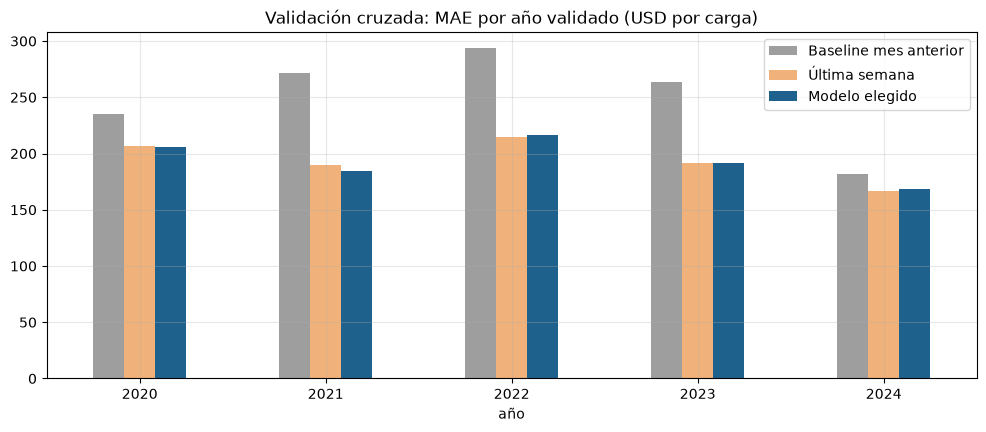

El modelo le gana al baseline en 5 de 5 años; mejora promedio del MAE: 22%


In [13]:
por_anio = cv.pivot(index="año", columns="modelo", values="MAE")
mostrar = {"Baseline ingenuo (mes anterior)": GRIS, "Referencia última semana": NARANJA, MEJOR: AZUL}
por_anio[list(mostrar)].plot.bar(color=list(mostrar.values()), rot=0)
plt.title("Validación cruzada: MAE por año validado (USD por carga)")
plt.legend(["Baseline mes anterior", "Última semana", "Modelo elegido"])
plt.show()
gana = (por_anio[MEJOR] < por_anio["Baseline ingenuo (mes anterior)"]).sum()
mejora_cv = 1 - tabla_cv.loc[MEJOR, "MAE"] / tabla_cv.loc["Baseline ingenuo (mes anterior)", "MAE"]
print(f"El modelo le gana al baseline en {gana} de 5 años; mejora promedio del MAE: {mejora_cv:.0%}")

**Interpretación.** El modelo elegido (hoja mínima de 60 y factor 0.25) tiene un MAE promedio de **193 USD por carga contra 249** del baseline del mes anterior (22% menos error) y le gana los **5 años** validados. Ridge (224) también mejora al baseline pero queda detrás, y el baseline estacional (898) no sirve para pronóstico mensual.

**Siendo honestos:** la referencia de la última semana logra prácticamente lo mismo (194). La mayor parte de la mejora viene de **usar la información más reciente**, no de la complejidad del algoritmo.

## 4. Métricas y comparación contra el baseline (prueba final)

Entrenamos la configuración elegida con todo el desarrollo (151 lanes elegibles en diciembre de 2024) y la medimos en los 22 meses de prueba.

| Métrica | Cómo se lee |
|---|---|
| **MAE** | Error promedio en USD por carga (métrica principal) |
| **RMSE** | Castiga más los errores grandes, que son los que rompen un presupuesto |
| **WAPE** | Error como % del gasto total |
| **Sesgo** | Pronóstico menos real: negativo = el presupuesto se queda corto |

In [14]:
modelo_final = crear_modelo(hgb(MEJOR_HOJA)).fit(desarrollo[ENTRADAS], desarrollo[TARGET])
real = prueba["tarifa"].to_numpy()
pred_modelo = a_tarifa(prueba, modelo_final.predict(prueba[ENTRADAS]), MEJOR_FACTOR)
pred_prueba = {"Modelo Gradient Boosting": pred_modelo, **{nombre: regla(prueba) for nombre, regla in BASELINES.items()}}

tabla_prueba = pd.DataFrame({nombre: metricas(real, pred) for nombre, pred in pred_prueba.items()}).T
tabla_prueba["Sesgo"] = [np.mean(pred - real) for pred in pred_prueba.values()]
tabla_prueba["Mejora del MAE vs mes anterior"] = 1 - tabla_prueba["MAE"] / tabla_prueba.loc["Baseline ingenuo (mes anterior)", "MAE"]
formatear(tabla_prueba, {"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "WAPE": "{:.1%}", "Sesgo": "{:,.0f}",
                         "Mejora del MAE vs mes anterior": "{:+.0%}"})

,MAE,RMSE,WAPE,Sesgo,Mejora del MAE vs mes anterior
Modelo Gradient Boosting,242,428,4.5%,-16,+19%
Baseline ingenuo (mes anterior),299,504,5.6%,-73,+0%
Baseline estacional (mismo mes año previo),632,"1,054",11.7%,-421,-111%
Referencia última semana,245,435,4.5%,-14,+18%


In [15]:
# ¿La mejora es real o suerte? Intervalo de confianza con bootstrap por MES (las lanes de un mes se mueven juntas)
resultados = prueba[["lane", "mes", "tarifa_lag1", "ultima_semana_lag1", "tarifa", "cambio_lane"]].assign(
    pred_modelo=pred_modelo, pred_ingenuo=prueba["tarifa_lag1"].to_numpy())
resultados["error_modelo"] = (resultados["pred_modelo"] - resultados["tarifa"]).abs()
resultados["error_ingenuo"] = (resultados["pred_ingenuo"] - resultados["tarifa"]).abs()

errores_mes = resultados.groupby("mes")[["error_modelo", "error_ingenuo"]].sum()
rng = np.random.default_rng(SEMILLA)
mejoras = [1 - m["error_modelo"].sum() / m["error_ingenuo"].sum()
           for m in (errores_mes.iloc[rng.integers(0, len(errores_mes), len(errores_mes))] for _ in range(2000))]
mejora = 1 - errores_mes["error_modelo"].sum() / errores_mes["error_ingenuo"].sum()
print(f"Mejora del MAE vs mes anterior: {mejora:.1%} (IC 95%: {np.percentile(mejoras, 2.5):.1%} a {np.percentile(mejoras, 97.5):.1%})")

Mejora del MAE vs mes anterior: 19.0% (IC 95%: 8.1% a 29.3%)


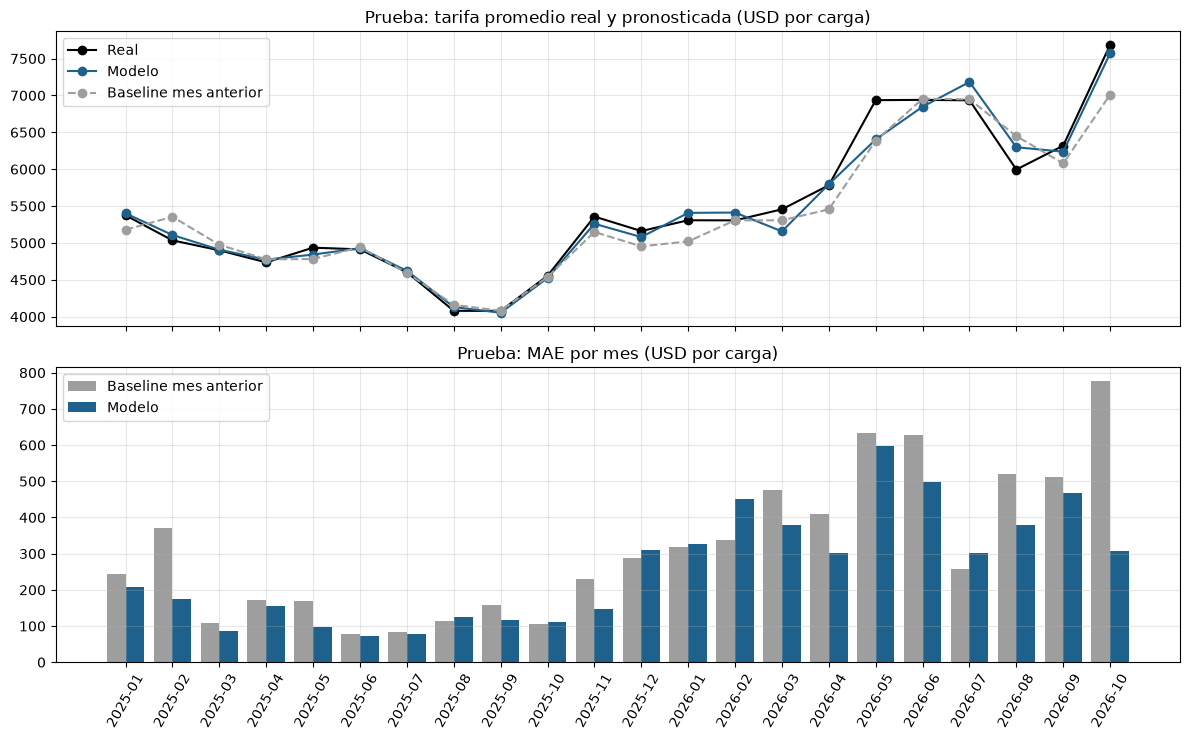

El modelo tiene menor MAE en 16 de 22 meses


In [16]:
por_mes = resultados.groupby("mes")[["tarifa", "pred_modelo", "pred_ingenuo", "error_modelo", "error_ingenuo"]].mean()
fig, ejes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
x, etiquetas = np.arange(len(por_mes)), por_mes.index.astype(str)
ejes[0].plot(x, por_mes["tarifa"], "o-", color="black", label="Real")
ejes[0].plot(x, por_mes["pred_modelo"], "o-", color=AZUL, label="Modelo")
ejes[0].plot(x, por_mes["pred_ingenuo"], "o--", color=GRIS, label="Baseline mes anterior")
ejes[0].set_title("Prueba: tarifa promedio real y pronosticada (USD por carga)")
ejes[0].legend()
ejes[1].bar(x - 0.2, por_mes["error_ingenuo"], 0.4, color=GRIS, label="Baseline mes anterior")
ejes[1].bar(x + 0.2, por_mes["error_modelo"], 0.4, color=AZUL, label="Modelo")
ejes[1].set_title("Prueba: MAE por mes (USD por carga)")
ejes[1].legend()
plt.xticks(x, etiquetas, rotation=60)
plt.tight_layout()
plt.show()
print(f"El modelo tiene menor MAE en {(por_mes['error_modelo'] < por_mes['error_ingenuo']).sum()} de {len(por_mes)} meses")

In [17]:
# ¿Dónde acierta y dónde falla? Según cuánto se movió realmente la tarifa ese mes
resultados["tipo_mes"] = pd.cut(resultados["cambio_lane"], [-np.inf, -0.05, -0.0001, 0.0001, 0.05, np.inf],
                                labels=["baja > 5%", "baja 0 a 5%", "sin cambio", "sube 0 a 5%", "sube > 5%"])
por_tipo = resultados.groupby("tipo_mes", observed=True).agg(lane_meses=("tarifa", "size"),
                                                             mae_modelo=("error_modelo", "mean"),
                                                             mae_baseline=("error_ingenuo", "mean"))
movimiento = resultados[resultados["cambio_lane"].abs() > 0.03]
acierto = (np.sign(np.log(movimiento["pred_modelo"] / movimiento["tarifa_lag1"])) == np.sign(movimiento["cambio_lane"])).mean()
print(f"Acierta la dirección en {acierto:.0%} de los {len(movimiento):,} lane-meses con movimiento de más de 3%")
formatear(por_tipo, {"mae_modelo": "{:,.0f}", "mae_baseline": "{:,.0f}"})

Acierta la dirección en 66% de los 613 lane-meses con movimiento de más de 3%


,lane_meses,mae_modelo,mae_baseline
tipo_mes,,,
baja > 5%,204,391,543
baja 0 a 5%,169,179,146
sin cambio,346,8,0
sube 0 a 5%,203,171,148
sube > 5%,273,521,705


**Interpretación.**
- En prueba el modelo tiene un **MAE de 242 USD por carga contra 299** del baseline del mes anterior: **19% menos error** (intervalo de 95% de 8.1% a 29.3%, así que aun en el peor caso es mejor). El RMSE baja de 504 a 428 y el WAPE de 5.6% a 4.5% del gasto.
- El **sesgo** baja de -73 a -16 USD: el baseline se queda corto en las alzas y el modelo casi no.
- Gana en **16 de 22 meses**, sobre todo en los movimientos fuertes (cambios de más de 5%), que son los que más le cuestan al negocio, y acierta la dirección en 66% de los movimientos de más de 3%.
- **Dónde falla:** en meses quietos, el baseline es un poco mejor, porque el modelo a veces traslada un movimiento de la última semana que no se sostuvo. Tampoco anticipa choques que aún no aparecen en los datos.
- La referencia de la última semana queda muy cerca (245): el valor está en usar la información más reciente.

### 4.1 ¿La pequeña mejora sobre la regla simple justifica mantener el algoritmo?

La comparación justa ya no es contra el mes anterior, sino contra la **alternativa más simple que usa la misma información**: la regla de la última semana. Medimos la diferencia en prueba con su propio intervalo de confianza (bootstrap por mes) y revisamos si se repite en la validación cruzada.

In [18]:
resultados["error_regla"] = (resultados["ultima_semana_lag1"] - resultados["tarifa"]).abs()
suma_mes = resultados.groupby("mes")[["error_modelo", "error_regla"]].sum()
rng_regla = np.random.default_rng(SEMILLA)
mejoras_regla = [1 - m["error_modelo"].sum() / m["error_regla"].sum()
                 for m in (suma_mes.iloc[rng_regla.integers(0, len(suma_mes), len(suma_mes))] for _ in range(2000))]
mae_mes = resultados.groupby("mes")[["error_modelo", "error_regla"]].mean()
cv_mae = cv.pivot(index="año", columns="modelo", values="MAE")
cv_rmse = cv.pivot(index="año", columns="modelo", values="RMSE")
REGLA = "Referencia última semana"
diferencia = resultados["error_regla"].mean() - resultados["error_modelo"].mean()

print(f"MAE en prueba: modelo {resultados['error_modelo'].mean():.0f} vs regla {resultados['error_regla'].mean():.0f} "
      f"| mejora {1 - suma_mes['error_modelo'].sum() / suma_mes['error_regla'].sum():.1%} "
      f"(IC 95%: {np.percentile(mejoras_regla, 2.5):.1%} a {np.percentile(mejoras_regla, 97.5):.1%})")
print(f"RMSE en prueba: modelo {tabla_prueba.loc['Modelo Gradient Boosting', 'RMSE']:.0f} vs regla {tabla_prueba.loc[REGLA, 'RMSE']:.0f}")
print(f"Meses de prueba en que el modelo tiene menor MAE que la regla: {(mae_mes['error_modelo'] < mae_mes['error_regla']).sum()} de {len(mae_mes)}")
print(f"Años de validación cruzada en que gana a la regla: MAE {(cv_mae[MEJOR] < cv_mae[REGLA]).sum()} de 5 | RMSE {(cv_rmse[MEJOR] < cv_rmse[REGLA]).sum()} de 5")
print(f"Diferencia: {diferencia:.1f} USD por carga, unos {diferencia * 200:,.0f} USD al mes con 200 cargas (supuesto)")

MAE en prueba: modelo 242 vs regla 245 | mejora 1.0% (IC 95%: 0.2% a 1.9%)
RMSE en prueba: modelo 428 vs regla 435
Meses de prueba en que el modelo tiene menor MAE que la regla: 11 de 22
Años de validación cruzada en que gana a la regla: MAE 3 de 5 | RMSE 5 de 5
Diferencia: 2.6 USD por carga, unos 512 USD al mes con 200 cargas (supuesto)


**Interpretación.** La mejora del algoritmo sobre la regla simple es **real pero pequeña**: 1.0% del MAE (unos 2.6 USD por carga), con un intervalo de 0.2% a 1.9% que apenas se separa de cero, y gana solo 11 de los 22 meses de prueba y 3 de los 5 años de validación. Lo único consistente es que reduce un poco los errores grandes (menor RMSE en los 5 años de validación y en la prueba). Además, esta prueba se reutilizó entre versiones, así que la diferencia real podría ser aún menor.

**Decisión.** Esa ventaja **no justifica, por ahora, que el algoritmo sea la herramienta principal**: cuesta reentrenarlo, monitorearlo y explicarlo, y la regla de la última semana es transparente y casi igual de buena. Recomendamos usar la **regla como base** y el Gradient Boosting como **retador** durante tres meses en paralelo, con un criterio fijado de antemano: se mantiene solo si reduce los errores grandes (RMSE) frente a la regla en la mayoría de esos meses.

## 5. Tres predicciones con su valor real

Para no escoger a mano los ejemplos tomamos, entre las lanes activas hoy, el renglón en el **percentil 10** del error (acierta), el **50** (típico) y el **90** (falla).

In [19]:
activas = resultados[resultados["lane"].isin(base.loc[base["mes"] == ULTIMO_MES, "lane"])].sort_values("error_modelo")
ejemplos = activas.iloc[[int(p * (len(activas) - 1)) for p in [0.1, 0.5, 0.9]]].assign(caso=["acierta (p10)", "típico (p50)", "falla (p90)"])
ejemplos = ejemplos.rename(columns={"tarifa_lag1": "mes anterior", "ultima_semana_lag1": "última semana",
                                    "pred_modelo": "pronóstico modelo", "tarifa": "real",
                                    "error_modelo": "error modelo", "error_ingenuo": "error baseline"})
columnas_usd = ["mes anterior", "última semana", "pronóstico modelo", "real", "error modelo", "error baseline"]
formatear(ejemplos[["caso", "lane", "mes"] + columnas_usd], {c: "${:,.0f}" for c in columnas_usd}).set_index("caso")

,lane,mes,mes anterior,última semana,pronóstico modelo,real,error modelo,error baseline
caso,,,,,,,,
acierta (p10),"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGT...",2025-05,"$5,150","$5,150","$5,145","$5,150",$5,$0
típico (p50),MEXICO CROSSINGS THROUGH SOUTH TEXAS → CHICAGO,2026-04,"$5,100","$5,300","$5,296","$5,475",$179,$375
falla (p90),SALINAS-WATSONVILLE CALIFORNIA → NEW YORK,2026-08,"$12,125","$11,900","$11,892","$11,075",$817,"$1,050"


**Qué nos dicen.**
- **Acierta** (Yakima Valley → Dallas, may-2025): la tarifa no cambió y el modelo quedó a 5 USD.
- **Típico** (Mexico Crossings, South Texas → Chicago, abr-2026): la última semana de marzo ya había subido a 5,300 contra una mediana de 5,100. El modelo dijo 5,296, la real fue 5,475: error de 179 USD contra 375 del baseline.
- **Falla** (Salinas-Watsonville → New York, ago-2026): la tarifa bajó casi 9% de golpe. El modelo se equivocó por 817 USD (el baseline por 1,050). Ninguno anticipa un choque que todavía no se ve en los datos.

## 6. De la predicción a la decisión de negocio

Tomamos el caso típico y lo convertimos en presupuesto. Supongamos que el distribuidor planea **20 cargas** en esa lane en abril de 2026 (es un supuesto, no un dato de la empresa).

In [20]:
CARGAS_LANE = 20   # supuesto, no es un dato de la empresa
caso = ejemplos.iloc[1]
presupuesto = pd.DataFrame({
    "pronóstico por carga": [caso["mes anterior"], caso["pronóstico modelo"]],
    "presupuesto del mes": [caso["mes anterior"] * CARGAS_LANE, caso["pronóstico modelo"] * CARGAS_LANE],
    "gasto real": caso["real"] * CARGAS_LANE,
}, index=["Método actual (repetir el mes anterior)", "Modelo"])
presupuesto["faltante del presupuesto"] = presupuesto["gasto real"] - presupuesto["presupuesto del mes"]
print(f"Lane: {caso['lane']} | mes: {caso['mes']} | {CARGAS_LANE} cargas")
formatear(presupuesto, {c: "${:,.0f}" for c in presupuesto.columns})

Lane: MEXICO CROSSINGS THROUGH SOUTH TEXAS → CHICAGO | mes: 2026-04 | 20 cargas


,pronóstico por carga,presupuesto del mes,gasto real,faltante del presupuesto
Método actual (repetir el mes anterior),"$5,100","$102,000","$109,500","$7,500"
Modelo,"$5,296","$105,927","$109,500","$3,573"


**Decisión 1, presupuesto.** Con el método actual el presupuesto de abril se habría quedado corto en unos **7,500 USD** en esta lane; con el modelo, en unos **3,600 USD**. La señal estaba en la última semana de marzo: el analista la ve al cierre del mes y ajusta el presupuesto antes de que llegue la factura.

**Decisión 2, spot o contrato.** El mismo criterio sirve hacia adelante. Para **noviembre de 2026** (sin valor real todavía), el modelo reentrenado con toda la historia proyecta lo siguiente:

In [21]:
# Proyección para noviembre de 2026 (NO mide desempeño: la tarifa real aún no existe)
MES_FUTURO = ULTIMO_MES + 1
base_hoy = base[base["lane"].isin(lanes_hoy)]
futuro = base_hoy[base_hoy["mes"] == ULTIMO_MES][["origin", "destination", "lane", "distancia"]].assign(mes=MES_FUTURO)
panel_hoy = crear_variables(pd.concat([base_hoy, futuro], ignore_index=True))
historia = panel_hoy.dropna(subset=["tarifa", "tarifa_lag1"])
filas_futuras = panel_hoy[panel_hoy["mes"] == MES_FUTURO].reset_index(drop=True)

modelo_produccion = crear_modelo(hgb(MEJOR_HOJA)).fit(historia[ENTRADAS], historia[TARGET])
filas_futuras["pronostico"] = a_tarifa(filas_futuras, modelo_produccion.predict(filas_futuras[ENTRADAS]), MEJOR_FACTOR)
filas_futuras["cambio_vs_octubre"] = filas_futuras["pronostico"] / filas_futuras["tarifa_lag1"] - 1
filas_futuras["señal"] = np.select([filas_futuras["cambio_vs_octubre"] > 0.03, filas_futuras["cambio_vs_octubre"] < -0.03],
                                   ["alza > 3%: cotizar contrato", "baja > 3%: quedarse en spot"], "estable: presupuesto normal")
print(f"{len(filas_futuras)} lanes con dato en octubre | cambio promedio pronosticado: {filas_futuras['cambio_vs_octubre'].mean():+.1%}")
print(filas_futuras["señal"].value_counts().to_string())
formatear(filas_futuras[filas_futuras["lane"].isin(ejemplos["lane"])][["lane", "tarifa_lag1", "ultima_semana_lag1", "pronostico", "cambio_vs_octubre", "señal"]],
          {"tarifa_lag1": "${:,.0f}", "ultima_semana_lag1": "${:,.0f}", "pronostico": "${:,.0f}", "cambio_vs_octubre": "{:+.1%}"}).set_index("lane")

70 lanes con dato en octubre | cambio promedio pronosticado: +0.1%
señal
estable: presupuesto normal    48
baja > 3%: quedarse en spot    11
alza > 3%: cotizar contrato    11


,tarifa_lag1,ultima_semana_lag1,pronostico,cambio_vs_octubre,señal
lane,,,,,
MEXICO CROSSINGS THROUGH SOUTH TEXAS → CHICAGO,"$3,900","$3,900","$3,962",+1.6%,estable: presupuesto normal
SALINAS-WATSONVILLE CALIFORNIA → NEW YORK,"$11,929","$12,482","$12,512",+4.9%,alza > 3%: cotizar contrato
"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGTON → DALLAS","$9,450","$9,000","$9,135",-3.3%,baja > 3%: quedarse en spot


**Interpretación.** Salinas-Watsonville → New York cerró octubre por arriba de su mediana y el modelo proyecta **+4.9%** para noviembre. Si es una lane de alto volumen para el distribuidor, la acción sería que el analista **pida cotización de un contrato de corto plazo a 2 o 3 transportistas** antes de que suba el mercado, y que el gerente de logística decida. Yakima Valley → Dallas se proyecta a la baja, así que conviene quedarse en spot.

**Precaución:** es una señal para decidir, no una cifra garantizada; el error típico del modelo es de 4.5% del gasto, así que un cambio proyectado de 3% a 5% debe tomarse con margen.

In [22]:
# Se guardan las predicciones para compararlas cuando USDA publique los datos reales
os.makedirs("data/processed", exist_ok=True)
resultados.drop(columns=["tipo_mes", "error_regla"]).assign(mes=resultados["mes"].astype(str)).to_csv("data/processed/predicciones_prueba.csv", index=False)
filas_futuras[["lane", "tarifa_lag1", "ultima_semana_lag1", "pronostico", "cambio_vs_octubre"]].assign(mes=str(MES_FUTURO)).to_csv(
    f"data/processed/proyeccion_{MES_FUTURO}.csv", index=False)
print("Guardado en data/processed: predicciones_prueba.csv y", f"proyeccion_{MES_FUTURO}.csv")

Guardado en data/processed: predicciones_prueba.csv y proyeccion_2026-11.csv


## 7. Resumen, recomendaciones y límites

**Resultados (los mismos de la presentación).**

| Pronóstico en prueba (ene-2025 a oct-2026) | MAE (USD por carga) | RMSE | WAPE | Sesgo |
|---|---|---|---|---|
| Modelo Gradient Boosting | **242** | **428** | **4.5%** | -16 |
| Baseline ingenuo (mes anterior) | 299 | 504 | 5.6% | -73 |
| Baseline estacional (mismo mes año previo) | 632 | 1,054 | 11.7% | |
| Referencia última semana | 245 | 435 | 4.5% | |

Mejora contra el mes anterior: **19%** en prueba (IC 95% de 8.1% a 29.3%) y **22%** en validación cruzada. Es una estimación algo optimista porque la prueba se midió en tres versiones. Contra la regla de la última semana, el modelo solo mejora 1.0% (IC 95% de 0.2% a 1.9%).

**Recomendación.** Usar al cierre de cada mes, en el área de compras de transporte, como base la regla de la última semana (simple y fácil de explicar) y correr el Gradient Boosting en paralelo durante tres meses como retador; se mantiene solo si reduce los errores grandes frente a la regla en la mayoría de esos meses. Indicador: WAPE del presupuesto de flete contra el gasto real, comparado con el método actual.

**Medido contra estimado.** El 19% es un resultado **medido** sobre tarifas de mercado de USDA. Cualquier ahorro en dinero para la empresa es **potencial** y solo se podrá afirmar al medirlo con sus tarifas reales.

**Límites.** Trabaja con tarifas de mercado y no con las pagadas por la empresa, no anticipa choques que aún no se ven, es algo peor que el baseline en meses quietos y aplica a lanes con al menos 36 meses de historia.

## Referencias
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3a ed.). OTexts. https://otexts.com/fpp3/
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- U.S. Department of Agriculture, Agricultural Marketing Service. (2026). *Refrigerated truck rates and availability* [Conjunto de datos; copia al 27 de octubre de 2026]. AgTransport. https://agtransport.usda.gov/d/acar-e3r8
- U.S. Energy Information Administration. (2026). *Weekly U.S. No 2 diesel retail prices* [Conjunto de datos]. https://www.eia.gov/dnav/pet/hist/LeafHandler.ashx?n=PET&s=EMD_EPD2D_PTE_NUS_DPG&f=W

## Declaración de uso de IA
Utilizamos un asistente de IA generativa (Claude, de Anthropic) principalmente como apoyo para la lluvia de ideas y para la depuración de código. Todas las decisiones de metodología, el análisis de resultados y las conclusiones fueron revisadas y validadas por el equipo, y todas las cifras provienen de la ejecución de este notebook.